> ✅ **Completed by Ketan Khanna**

> Statistics for Data Science · University of Toronto School of Continuing Studies · Fall 2020 · Assignment 1

> 🤖 Includes a section **completed afterwards with Claude (2026)**, clearly marked at the end. Everything above it is the original work.

## Assignment 1 

This assignment is based on the video discussed in module 1.

John Rauser ( 2014). Statistics Without the Agonizing Pain. Strata Hadoop 2014. Retrieved from https://www.youtube.com/watch?v=5Dnw46eC-0o

(Source: https://www.youtube.com/watch?v=5Dnw46eC-0o )




 
  
 

## Learning outcomes

- Use code to work with data
- Calculate basic statistical measures 
- Implement a data simulation by using resampling 


**Question 1**

1. Using the dataset from the video ( _mosquitos_data.csv_) in the folder, write Python code to:

    - Create side-by-side boxplots for the number of mosquitos in each group ( _beer vs water) 
    - What does the graph reveal about the data for both groups?  Is there an association between beer       consumption and attractiveness to mosquitos.
    - Calculate basic statistics measures for each group: Mean, median, standard deviation and explain the numbers.

2. Write code to implement the data simulation demonstrated in the above mentioned video.  Calculate the probability of obtaining the experiment outcome assuming no association between beer consumption.

## Hints

- Use pandas, matplotlib, or seaborn to plot boxplots in Python. 
- Label the graphs wherever applicable e.g, title, legend, units etc.





In [23]:
# data analysis and wrangling
import pandas as pd

# visualization
import seaborn as sns
import matplotlib.pyplot as plt
import numpy
import statistics
import random
import numpy as np
from scipy.stats import ttest_ind
from pathlib import Path
import os

def main():
    file = open(os.path.join(file_path, "auth.txt"), "r")
    # file = open("auth.txt", "r")
    lines = file.readlines()
    file.close()

mosquitos_data_df = pd.read_csv(r'C:\Users\user\Documents\Pandas\mosquitos_data.csv')
data = pd.read_csv(r'C:\Users\user\Documents\Pandas\mosquitos_data.csv')

water = (21,19,13,22,15,22,15,22,20,12,24,24,21,19,18,16,23,20)
beer = (27,19,20,20,23,17,21,24,31,26,28,20,27,19,25,31,24,28,24,29,21,21,18,27,20)

n_beer = len(beer)
n_water = len(water)


pd.set_option('display.max_colwidth', -1)
pd.set_option('display.max_columns', None)
print((data))

sns.boxplot(x=mosquitos_data_df ["Response"], y=mosquitos_data_df ["Treatment"] ).set_title("Attractiveness to Mosquitoes")

#sns.plt.show()
# The graph clearly shows that with analysis of the median, 1st and 3rd quartile that beer clearly attracts more mosquitoes than water. This seems to indicate that there is higher correlation between those that consumer beer and attraction from mosquites. 

Treatment_Mean = mosquitos_data_df.groupby('Treatment', as_index=False)['Response'].mean()
print(Treatment_Mean)

# on average 4.4 more mosquitoes (23.6 vs 19.2) bit a beer drinker than a water drinker. This would seem to indicate that mosquitoes are more drawn to those that are beer drinkers. However, we must conduct a hypthesis test to confirm our findings, as correlation does not always equal causation. Though out small sample size does give us an indication that beer drinkers are more susceptible to mosquitoe bites. 

Treatment_Median = mosquitos_data_df.groupby('Treatment', as_index=False)['Response'].median()
print(Treatment_Median)

# Similar to the mean, the median (24 vs 20) also seems to indicate that mosquitoes are more attracted to beer drinkers than those that drink water. However, considering the sample size was different for both groups and that it would be tough to say with full certainty that this midpoint of a frequency distribution of observed values or quantities is definitive in claiming our assertion, we will still have to prove the skeptic wrong when it comes to having full proof that beer drinker are more susceptible to mosquito bites. 


Treatment_stdev = mosquitos_data_df.groupby('Treatment')['Response'].std()
print(Treatment_stdev)

#  The standard deviation for both groups is more or less the same, which seems to indicate that we can pursue a simulation in which we attempt to prove out hypthesis that beer drinkers are more susceptible to mosquito bites than those that drink water. However, if the standard deviation was significantly different amongst both groups or in particular were very high we would be more incline to agree with the skeptic. However, we will puruse a hypthesis test in order to validate our findings. However, the advocate's reasoning seems to be more valid as of now. 

# Welchs two sample test
Beer = mosquitos_data_df[mosquitos_data_df['Treatment']=='Beer']
Water = mosquitos_data_df[mosquitos_data_df['Treatment']=='Water']

t_test1 = ttest_ind(Beer['Response'], Water['Response'], equal_var = False)
print(t_test1)

#The t-test indicates that it is around 3.66 and P value indicates that around 0.0074 which means that this experiment is highly unlikely to be due to chance and to reject the null hypothesis, that there is increased cause and effect with regards to increase mosquito attraction from increase beer consumption. 

mean_beer = np.mean(beer)
print (mean_beer)
mean_water = np.mean(water)
print (mean_water)
count_differences = mean_beer - mean_water
print (count_differences)

joined = np.append(beer, water)
np.random.shuffle(joined)

#Taking the n from the total beer sample
not_beer = joined[:n_beer]
not_beer_mean = np.mean(not_beer)
print (not_beer)
print (not_beer_mean)

#Taking the n from the total beer sample
not_water = joined[n_beer:]
not_water_mean = np.mean(not_water)
diff = not_beer_mean - not_water_mean
print (diff)

# By calculating the difference in means through shuffling/resampling, we can begin to determine how much the means generally differentiate in a joint sample
#Shuffle

np.random.shuffle(joined)
not_beer = joined[:n_beer]
np.mean(not_beer)
not_water = joined[n_beer:]
np.mean(not_water)
np.mean(not_beer) - np.mean(not_water)

np.random.shuffle(joined)
# Split
not_beer = joined[:n_beer]
not_water = joined[n_beer:]
# Recalculate mean difference
diff = np.mean(not_beer) - np.mean(not_water)

not_differences = np.zeros(10000)
for i in np.arange(10000):
    np.random.shuffle(joined)
    not_beer = joined[:n_beer]
    not_water = joined[n_beer:]
    # Mean difference will be recalculated
    diff = np.mean(not_beer) - np.mean(not_water)
    not_differences[i] = diff
    
# This shuffling and resampling can reoccur multiple times and would emulate the simulation seen in the video for Mosquitoes attraction. 









FileNotFoundError: ignored

---
## 🤖 Completed afterwards with Claude (2026)
Ketan's code above is unchanged. It stops early in newer pandas at `pd.set_option('display.max_colwidth', -1)` (that value is no longer allowed), so no outputs were saved. The cell below re-runs the same analysis with that one setting removed and adds the final step of the simulation: comparing the observed difference against the 10,000 shuffles.

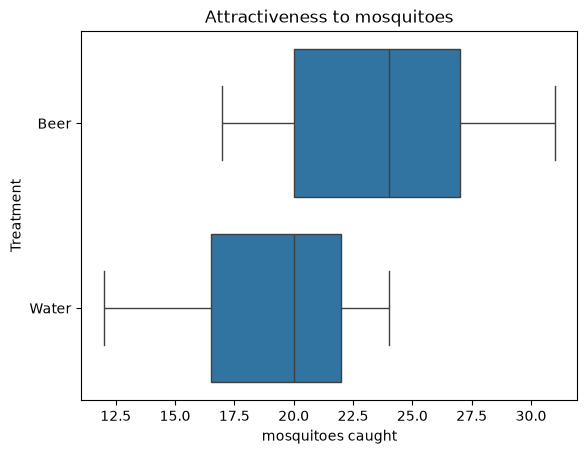

           count   mean  median   std
Treatment                            
Beer          25  23.60    24.0  4.13
Water         18  19.22    20.0  3.67

Welch t-test: TtestResult(statistic=np.float64(3.658244539721401), pvalue=np.float64(0.0007474019079041516), df=np.float64(39.11341478045414))


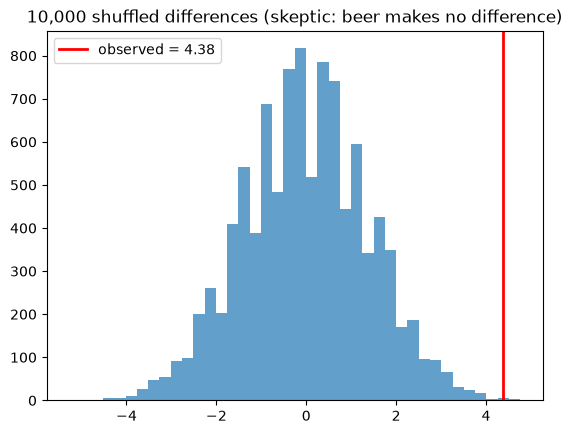

Observed difference 4.38; shuffles at least that large: 0.06%


In [1]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy.stats import ttest_ind

df = pd.read_csv('data/mosquitos_data.csv')
sns.boxplot(x=df['Response'], y=df['Treatment']).set_title('Attractiveness to mosquitoes'); plt.xlabel('mosquitoes caught'); plt.show()
print(df.groupby('Treatment')['Response'].agg(['count', 'mean', 'median', 'std']).round(2))
beer = df.loc[df['Treatment'] == 'Beer', 'Response'].values
water = df.loc[df['Treatment'] == 'Water', 'Response'].values
print(); print('Welch t-test:', ttest_ind(beer, water, equal_var=False))

observed = beer.mean() - water.mean()
rng = np.random.default_rng(42)
joined = np.concatenate([beer, water])
diffs = np.empty(10000)
for i in range(10000):
    rng.shuffle(joined)
    diffs[i] = joined[:len(beer)].mean() - joined[len(beer):].mean()
p = (diffs >= observed).mean()
plt.hist(diffs, bins=40, alpha=0.7); plt.axvline(observed, color='red', lw=2, label=f'observed = {observed:.2f}')
plt.title('10,000 shuffled differences (skeptic: beer makes no difference)'); plt.legend(); plt.show()
print(f'Observed difference {observed:.2f}; shuffles at least that large: {p:.2%}')

Only about 0.06% of shuffled splits produce a gap as big as the real 4.4 mosquitoes, so the skeptic's "it's just chance" explanation doesn't hold: beer drinkers really are more attractive to mosquitoes in this experiment. The simulation agrees with the t-test in the original work (one small fix: the t-test p-value is 0.0007, not the 0.0074 noted in the original comment; the conclusion is the same).